# Joint Plot (Scatter + Marginals)

**Family:** Correlation &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Correlation:* Show the relationship between two or more variables.

## Design purpose

A scatter plot with the marginal distribution of each variable drawn along its axis. The joint relationship and both individual distributions show together.

## When to use

- Show both the relationship and each variable's skew or outliers
- Explore two key variables in detail

## Avoid when

- There are more than two or three groups (marginals get crowded)
- Space is tight (dashboard tiles)

## Alternatives

- Scatter plot
- Hexbin with marginal histograms

## Example

House size vs. sale price for 400 homes (synthetic, right-skewed prices).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
pio.templates["vizlib"] = go.layout.Template(layout=dict(
    colorway=PALETTE, font=dict(family="Helvetica, Arial, sans-serif", size=13, color="#0b0b0b"),
    paper_bgcolor="#fcfcfb", plot_bgcolor="#fcfcfb", title=dict(x=0.02, xanchor="left"),
    xaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
    yaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
))
pio.templates.default = "plotly_white+vizlib"
pio.renderers.default = "plotly_mimetype+notebook_connected"

### Data

In [2]:
rng = np.random.default_rng(17)
size = rng.gamma(9, 18, 400)                                 # m²
price = np.exp(10.8 + 0.0062 * size + rng.normal(0, 0.22, 400)) / 1000   # $k
df = pd.DataFrame({"size_m2": size, "price_k": price})
x, y = "size_m2", "price_k"
labels = dict(x="Living area (m²)", y="Sale price ($k)", title="House size vs. price")
df.describe().round(0)

,size_m2,price_k
count,400.0,400.0
mean,160.0,147.0
std,53.0,68.0
min,54.0,46.0
25%,122.0,100.0
50%,157.0,132.0
75%,191.0,175.0
max,366.0,634.0


### Plot

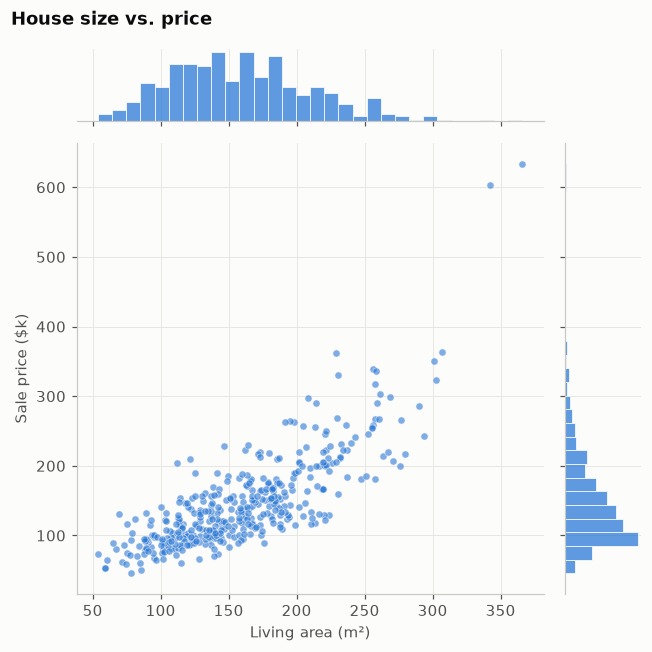

In [3]:
import seaborn as sns
g = sns.jointplot(data=df, x=x, y=y, height=6, color=PALETTE[0],
                  joint_kws=dict(s=22, alpha=0.6, edgecolor="#fcfcfb", linewidth=0.5),
                  marginal_kws=dict(bins=30, edgecolor="#fcfcfb", linewidth=0.5))
g.set_axis_labels(labels["x"], labels["y"])
g.figure.suptitle(labels["title"], x=0.02, ha="left", weight="bold")
g.figure.tight_layout()
fig = g.figure
plt.show()

## How to read it

The centre panel shows price rising with size. The histograms on the edges show both variables are right-skewed: most homes are mid-sized, with a long tail of large, expensive ones.

## The same chart in other libraries

Each version uses the example data above. Pick the library that fits your stack: matplotlib/seaborn for static and print figures, plotly for interactive HTML, Altair for concise declarative specs.

### plotly

In [4]:
import plotly.express as px
fig = px.scatter(df, x=x, y=y, marginal_x="histogram", marginal_y="histogram", opacity=0.6,
                 color_discrete_sequence=PALETTE, labels={x: labels["x"], y: labels["y"]},
                 title=labels["title"])
fig.update_layout(height=560)
fig.show()

## Try it with real data

**Source:** plotly.express.data.gapminder() — Gapminder 2007, bundled with plotly

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [5]:
import plotly.express as px
df = px.data.gapminder().query("year == 2007")
x, y = "gdpPercap", "lifeExp"
labels = dict(x="GDP per capita (USD)", y="Life expectancy (years)",
              title="Income vs. life expectancy, 142 countries (2007)")
df[[x, y]].describe().round(0)

,gdpPercap,lifeExp
count,142.0,142.0
mean,11680.0,67.0
std,12860.0,12.0
min,278.0,40.0
25%,1625.0,57.0
50%,6124.0,72.0
75%,18009.0,76.0
max,49357.0,83.0


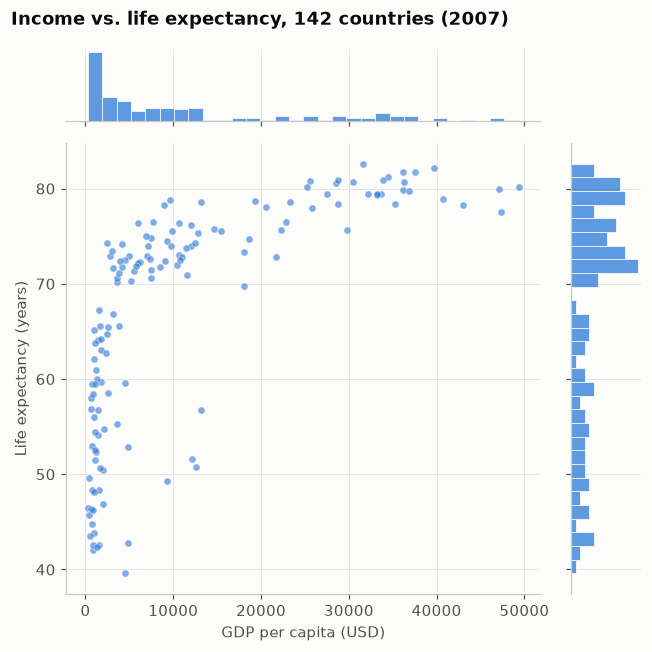

In [6]:
import seaborn as sns
g = sns.jointplot(data=df, x=x, y=y, height=6, color=PALETTE[0],
                  joint_kws=dict(s=22, alpha=0.6, edgecolor="#fcfcfb", linewidth=0.5),
                  marginal_kws=dict(bins=30, edgecolor="#fcfcfb", linewidth=0.5))
g.set_axis_labels(labels["x"], labels["y"])
g.figure.suptitle(labels["title"], x=0.02, ha="left", weight="bold")
g.figure.tight_layout()
fig = g.figure
plt.show()

---
Standalone script: [`joint_plot.py`](joint_plot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)